In [ ]:
# إعادة ربط Google Drive بشكل نظيف
from google.colab import drive
drive.flush_and_unmount() if __import__('os').path.ismount('/content/drive') else None
drive.mount('/content/drive', force_remount=True, timeout_ms=300000)
print(__import__('os').listdir('/content/drive/MyDrive/crnn_cache'))

In [ ]:
# التحقق من وجود GPU
import torch; print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NO GPU')

True NVIDIA A100-SXM4-40GB


In [ ]:
# الخطوة 1: التحقق من الملفات وتحميل أوزان AST
import os, numpy as np, torch, transformers
from transformers import ASTForAudioClassification
print(torch.__version__, transformers.__version__, torch.cuda.get_device_name(0))

C   = '/content/drive/MyDrive/crnn_cache'
OUT = '/content/drive/MyDrive/ast_runs'; os.makedirs(OUT, exist_ok=True)
CLASSES = ['I','E','D','Wheeze','Stridor','Rhonchi']

for s in ['train', 'test']:
    X = np.load(f'{C}/{s}_X.npy', mmap_mode='r')
    Y = np.load(f'{C}/{s}_Yf.npy', mmap_mode='r')
    n = np.load(f'{C}/{s}_names.npy')
    yc = np.asarray(Y).max(1) > 0.5
    print(s, X.shape, X.dtype, Y.shape, Y.dtype, len(n), dict(zip(CLASSES, yc.sum(0).tolist())))
fold = np.load(f'{C}/train_fold.npy'); print('fold sizes', np.bincount(fold))

m = ASTForAudioClassification.from_pretrained(
        'MIT/ast-finetuned-audioset-10-10-0.4593',
        num_labels=6, ignore_mismatched_sizes=True).cuda()
cfg = m.config
print('max_length', cfg.max_length, '| mel', cfg.num_mel_bins, '| patch', cfg.patch_size,
      '| stride f/t', cfg.frequency_stride, cfg.time_stride)
x = torch.randn(2, 1024, 128, device='cuda')
with torch.autocast('cuda', dtype=torch.bfloat16):
    o = m(input_values=x, output_hidden_states=True)
print('logits', tuple(o.logits.shape), '| tokens', tuple(o.hidden_states[-1].shape),
      '| params %.1fM' % (sum(p.numel() for p in m.parameters()) / 1e6))
del m, o; torch.cuda.empty_cache()

2.11.0+cu128 5.16.1 NVIDIA A100-SXM4-40GB
train (7809, 128, 938) float16 (7809, 938, 6) uint8 7809 {'I': 7510, 'E': 4593, 'D': 3076, 'Wheeze': 2253, 'Stridor': 253, 'Rhonchi': 944}
test (1956, 128, 938) float16 (1956, 938, 6) uint8 1956 {'I': 1935, 'E': 950, 'D': 368, 'Wheeze': 405, 'Stridor': 12, 'Rhonchi': 296}
fold sizes [2051 1334 1341 1510 1573]


config.json:   0%|          | 0.00/26.8k [00:00<?, ?B/s]

[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `527`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                     | Status   |                                                                                         
------------------------+----------+-----------------------------------------------------------------------------------------
classifier.dense.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([6, 768])
classifier.dense.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([6])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


max_length 1024 | mel 128 | patch 16 | stride f/t 10 10
logits (2, 6) | tokens (2, 1214, 768) | params 86.2M


In [ ]:
# الخطوة 2: تعريف البيانات والنموذج الإطاري والخسارة + اختبار سريع
import time, torch.nn as nn, torch.nn.functional as F, torchaudio.transforms as TA
from torch.utils.data import Dataset, DataLoader
from transformers import ASTModel

NAME, MU, SD, T, TP = 'MIT/ast-finetuned-audioset-10-10-0.4593', -8.5267, 2.4603, 938, 1024
Xtr = np.load(f'{C}/train_X.npy'); Ytr = np.load(f'{C}/train_Yf.npy')
Xte = np.load(f'{C}/test_X.npy');  Yte = np.load(f'{C}/test_Yf.npy')
fold = np.load(f'{C}/train_fold.npy')

class DS(Dataset):
    def __init__(s, X, Y, idx, aug=False):
        s.X, s.Y, s.idx, s.aug = X, Y, idx, aug
        s.fm, s.tm = TA.FrequencyMasking(16), TA.TimeMasking(40)
    def __len__(s): return len(s.idx)
    def __getitem__(s, i):
        j = s.idx[i]
        x = (torch.from_numpy(s.X[j].astype(np.float32)) - MU) / (2 * SD)   # (128,938)
        if s.aug: x = s.tm(s.fm(s.fm(x[None])))[0]
        x = F.pad(x, (0, TP - T)).T                                        # (1024,128)
        return x, torch.from_numpy(s.Y[j].astype(np.float32))              # (938,6)

class ASTFrame(nn.Module):
    def __init__(s):
        super().__init__()
        s.ast  = ASTModel.from_pretrained(NAME)
        s.head = nn.Sequential(nn.LayerNorm(768), nn.Dropout(0.1), nn.Linear(768, 6))
    def forward(s, x):
        h = s.ast(input_values=x).last_hidden_state[:, 2:]                  # (B,1212,768)
        h = h.reshape(x.size(0), 12, 101, 768).mean(1)                     # (B,101,768)
        f = F.interpolate(s.head(h).transpose(1, 2), size=TP, mode='linear',
                          align_corners=False)[..., :T]                   # (B,6,938)
        return f.transpose(1, 2)                                           # frame logits (B,938,6)

def clip_prob(fl):                                                         # same as CNN-BiGRU
    return F.avg_pool1d(torch.sigmoid(fl.float()).transpose(1, 2), 9, 1, 4).amax(-1)

def pos_weights(idx):
    yf = Ytr[idx].reshape(-1, 6).mean(0); yc = Ytr[idx].max(1).mean(0)
    pw = lambda p: torch.tensor(np.clip((1 - p) / np.maximum(p, 1e-6), 1, 10), dtype=torch.float32)
    return pw(yf).cuda(), pw(yc).cuda()

def loss_fn(fl, y, pwf, pwc):
    lf = F.binary_cross_entropy_with_logits(fl.float(), y, pos_weight=pwf)
    p, yc = clip_prob(fl).clamp(1e-6, 1 - 1e-6), y.amax(1)
    lc = -(pwc * yc * p.log() + (1 - yc) * (1 - p).log()).mean()
    return lf + lc

# اختبار سريع على fold 0
tr = np.where(fold != 0)[0]; pwf, pwc = pos_weights(tr)
print('pw frame', pwf.cpu().numpy().round(2), '\npw clip ', pwc.cpu().numpy().round(2))
xb, yb = next(iter(DataLoader(DS(Xtr, Ytr, tr, aug=True), batch_size=16, shuffle=True)))
m = ASTFrame().cuda(); torch.cuda.reset_peak_memory_stats(); t0 = time.time()
with torch.autocast('cuda', dtype=torch.bfloat16):
    fl = m(xb.cuda()); L = loss_fn(fl, yb.cuda(), pwf, pwc)
L.backward(); torch.cuda.synchronize()
print('x', tuple(xb.shape), '| frame logits', tuple(fl.shape), '| clip', tuple(clip_prob(fl).shape),
      '| loss %.3f | step %.2fs | peak mem %.1f GB' % (L.item(), time.time() - t0, torch.cuda.max_memory_allocated() / 1e9))
del m, fl, L; torch.cuda.empty_cache()

pw frame [ 3.54  6.43  8.67 10.   10.   10.  ] 
pw clip  [ 1.    1.    1.64  2.7  10.    7.03]


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.dense.bias       | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


x (16, 1024, 128) | frame logits (16, 938, 6) | clip (16, 6) | loss 2.206 | step 0.50s | peak mem 8.1 GB


In [ ]:
# الخطوة 3: تدريب AST لخمسة folds مع حفظ كل epoch واستئناف تلقائي
import json, math
from sklearn.metrics import roc_auc_score

EPOCHS, PAT, BS, LR_B, LR_H, WD, WU = 25, 5, 16, 2e-5, 1e-3, 1e-4, 1

def evaluate(m, dl, pwf, pwc):
    m.eval(); P, Ys, L = [], [], 0.
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
        for x, y in dl:
            x, y = x.cuda(non_blocking=True), y.cuda(non_blocking=True)
            fl = m(x); L += loss_fn(fl, y, pwf, pwc).item() * len(x)
            P.append(clip_prob(fl).cpu()); Ys.append(y.amax(1).cpu())
    P, Ys = torch.cat(P).numpy(), torch.cat(Ys).numpy()
    return L / len(P), [float(roc_auc_score(Ys[:, c], P[:, c])) for c in range(6)], P

for k in range(5):
    f_best, f_last, f_oof, f_hist = [f'{OUT}/ast_fold{k}{s}' for s in ('.pt', '_last.pt', '_oof.npy', '_hist.json')]
    if os.path.exists(f_hist) and json.load(open(f_hist)).get('done'): print(f'fold {k} already done'); continue
    tr, va = np.where(fold != k)[0], np.where(fold == k)[0]
    pwf, pwc = pos_weights(tr)
    dtr = DataLoader(DS(Xtr, Ytr, tr, aug=True), BS, shuffle=True, num_workers=4,
                     pin_memory=True, drop_last=True, persistent_workers=True)
    dva = DataLoader(DS(Xtr, Ytr, va), 32, num_workers=4, pin_memory=True)
    m = ASTFrame().cuda()
    opt = torch.optim.AdamW([{'params': m.ast.parameters(),  'lr': LR_B},
                             {'params': m.head.parameters(), 'lr': LR_H}], weight_decay=WD)
    tot, wu = EPOCHS * len(dtr), WU * len(dtr)
    sch = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: s / wu if s < wu
                                            else 0.5 * (1 + math.cos(math.pi * (s - wu) / (tot - wu))))
    ep0, best, bad = 0, -1., 0
    hist = {'tr_loss': [], 'va_loss': [], 'va_auc': [], 'va_auc_cls': []}
    if os.path.exists(f_last):
        ck = torch.load(f_last, map_location='cuda', weights_only=False)
        m.load_state_dict(ck['m']); opt.load_state_dict(ck['opt']); sch.load_state_dict(ck['sch'])
        ep0, best, bad, hist = ck['ep'] + 1, ck['best'], ck['bad'], ck['hist']
        print(f'fold {k}: resuming from epoch {ep0}')
    for ep in range(ep0, EPOCHS):
        if bad >= PAT: break
        m.train(); t0, s = time.time(), 0.
        for x, y in dtr:
            x, y = x.cuda(non_blocking=True), y.cuda(non_blocking=True)
            with torch.autocast('cuda', dtype=torch.bfloat16):
                L = loss_fn(m(x), y, pwf, pwc)
            opt.zero_grad(set_to_none=True); L.backward()
            nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); sch.step(); s += L.item()
        vl, auc, P = evaluate(m, dva, pwf, pwc); ma = float(np.mean(auc))
        hist['tr_loss'].append(s / len(dtr)); hist['va_loss'].append(vl)
        hist['va_auc'].append(ma); hist['va_auc_cls'].append(auc)
        if ma > best:
            best, bad = ma, 0; hist['best_ep'] = ep
            torch.save(m.state_dict(), f_best); np.save(f_oof, P)
        else: bad += 1
        torch.save({'m': m.state_dict(), 'opt': opt.state_dict(), 'sch': sch.state_dict(),
                    'ep': ep, 'best': best, 'bad': bad, 'hist': hist}, f_last)
        json.dump(hist, open(f_hist, 'w'))
        print(f'fold {k} ep {ep:2d} | tr {hist["tr_loss"][-1]:.4f} | va {vl:.4f} | AUC {ma:.4f} [' +
              ' '.join(f'{a:.2f}' for a in auc) + f'] | best {best:.4f} | {time.time()-t0:.0f}s', flush=True)
    hist['done'] = True; json.dump(hist, open(f_hist, 'w'))
    if os.path.exists(f_last): os.remove(f_last)
    print(f'>>> fold {k}: best val Macro-AUC {best:.4f} @ epoch {hist["best_ep"]}')
    del m, opt, dtr, dva; torch.cuda.empty_cache()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.dense.bias       | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


fold 0 ep  0 | tr 1.4464 | va 1.3059 | AUC 0.7886 [0.69 0.78 0.77 0.85 0.75 0.89] | best 0.7886 | 53s
fold 0 ep  1 | tr 1.1155 | va 1.2377 | AUC 0.8212 [0.82 0.81 0.78 0.84 0.77 0.90] | best 0.8212 | 52s
fold 0 ep  2 | tr 0.9698 | va 1.1421 | AUC 0.8301 [0.78 0.84 0.79 0.87 0.78 0.91] | best 0.8301 | 62s
fold 0 ep  3 | tr 0.8631 | va 1.2064 | AUC 0.8393 [0.84 0.84 0.80 0.88 0.78 0.90] | best 0.8393 | 51s
fold 0 ep  4 | tr 0.7794 | va 1.2490 | AUC 0.8392 [0.81 0.85 0.79 0.87 0.81 0.91] | best 0.8393 | 48s
fold 0 ep  5 | tr 0.7174 | va 1.2940 | AUC 0.8563 [0.85 0.86 0.81 0.87 0.83 0.92] | best 0.8563 | 57s
fold 0 ep  6 | tr 0.6558 | va 1.4606 | AUC 0.8477 [0.84 0.86 0.80 0.86 0.80 0.92] | best 0.8563 | 54s
fold 0 ep  7 | tr 0.5917 | va 1.4506 | AUC 0.8530 [0.84 0.86 0.81 0.86 0.84 0.91] | best 0.8563 | 68s
fold 0 ep  8 | tr 0.5367 | va 1.5498 | AUC 0.8475 [0.84 0.86 0.79 0.87 0.81 0.91] | best 0.8563 | 60s
fold 0 ep  9 | tr 0.4949 | va 1.8466 | AUC 0.8399 [0.86 0.85 0.78 0.86 0.79 0.88] 

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.dense.bias       | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


fold 1 ep  0 | tr 1.4408 | va 1.2889 | AUC 0.8128 [0.65 0.85 0.76 0.90 0.81 0.90] | best 0.8128 | 63s
fold 1 ep  1 | tr 1.1151 | va 1.1828 | AUC 0.8303 [0.64 0.85 0.81 0.89 0.84 0.95] | best 0.8303 | 53s
fold 1 ep  2 | tr 0.9751 | va 1.2381 | AUC 0.8469 [0.71 0.86 0.83 0.92 0.82 0.95] | best 0.8469 | 54s
fold 1 ep  3 | tr 0.8720 | va 1.2073 | AUC 0.8416 [0.71 0.84 0.80 0.92 0.85 0.94] | best 0.8469 | 52s
fold 1 ep  4 | tr 0.7821 | va 1.1617 | AUC 0.8495 [0.72 0.86 0.83 0.91 0.83 0.94] | best 0.8495 | 53s
fold 1 ep  5 | tr 0.7249 | va 1.1362 | AUC 0.8636 [0.74 0.85 0.84 0.93 0.88 0.95] | best 0.8636 | 54s
fold 1 ep  6 | tr 0.6633 | va 1.3603 | AUC 0.8498 [0.71 0.86 0.84 0.92 0.83 0.95] | best 0.8636 | 52s
fold 1 ep  7 | tr 0.6039 | va 1.4043 | AUC 0.8658 [0.74 0.87 0.84 0.93 0.87 0.95] | best 0.8658 | 54s
fold 1 ep  8 | tr 0.5482 | va 1.3096 | AUC 0.8660 [0.75 0.86 0.82 0.93 0.88 0.95] | best 0.8660 | 53s
fold 1 ep  9 | tr 0.4982 | va 1.6027 | AUC 0.8578 [0.75 0.87 0.83 0.92 0.83 0.94] 

... (5 outputs left out)

fold 3 ep  0 | tr 1.4480 | va 1.1086 | AUC 0.8292 [0.77 0.85 0.78 0.87 0.77 0.94] | best 0.8292 | 59s
fold 3 ep  1 | tr 1.1338 | va 1.0734 | AUC 0.8446 [0.81 0.85 0.81 0.88 0.78 0.94] | best 0.8446 | 52s
fold 3 ep  2 | tr 0.9949 | va 0.9415 | AUC 0.8554 [0.85 0.87 0.86 0.91 0.69 0.95] | best 0.8554 | 58s
fold 3 ep  3 | tr 0.8933 | va 0.9654 | AUC 0.8674 [0.86 0.88 0.84 0.91 0.77 0.95] | best 0.8674 | 58s
fold 3 ep  4 | tr 0.8089 | va 0.9759 | AUC 0.8501 [0.85 0.88 0.85 0.91 0.66 0.95] | best 0.8674 | 57s
fold 3 ep  5 | tr 0.7347 | va 1.1059 | AUC 0.8405 [0.85 0.90 0.85 0.90 0.62 0.92] | best 0.8674 | 56s
fold 3 ep  6 | tr 0.6581 | va 1.1292 | AUC 0.8364 [0.83 0.88 0.84 0.90 0.61 0.94] | best 0.8674 | 56s
fold 3 ep  7 | tr 0.6024 | va 1.0868 | AUC 0.8491 [0.85 0.89 0.84 0.91 0.65 0.95] | best 0.8674 | 55s
fold 3 ep  8 | tr 0.5481 | va 1.3445 | AUC 0.8390 [0.84 0.89 0.82 0.91 0.62 0.95] | best 0.8674 | 60s
>>> fold 3: best val Macro-AUC 0.8674 @ epoch 3


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.dense.bias       | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


fold 4 ep  0 | tr 1.4500 | va 1.0933 | AUC 0.8311 [0.88 0.86 0.76 0.84 0.76 0.89] | best 0.8311 | 60s
fold 4 ep  1 | tr 1.1271 | va 1.0306 | AUC 0.8264 [0.82 0.86 0.76 0.88 0.71 0.93] | best 0.8311 | 56s
fold 4 ep  2 | tr 0.9875 | va 0.9766 | AUC 0.8495 [0.81 0.90 0.77 0.91 0.77 0.93] | best 0.8495 | 70s
fold 4 ep  3 | tr 0.8907 | va 0.8892 | AUC 0.8660 [0.85 0.89 0.81 0.90 0.81 0.94] | best 0.8660 | 64s
fold 4 ep  4 | tr 0.8068 | va 0.9635 | AUC 0.8609 [0.89 0.91 0.77 0.90 0.75 0.93] | best 0.8660 | 59s
fold 4 ep  5 | tr 0.7283 | va 0.9096 | AUC 0.8716 [0.90 0.91 0.77 0.90 0.81 0.94] | best 0.8716 | 60s
fold 4 ep  6 | tr 0.6817 | va 1.0031 | AUC 0.8729 [0.90 0.91 0.80 0.90 0.79 0.94] | best 0.8729 | 60s
fold 4 ep  7 | tr 0.6172 | va 1.0780 | AUC 0.8715 [0.87 0.91 0.78 0.91 0.82 0.94] | best 0.8729 | 56s
fold 4 ep  8 | tr 0.5673 | va 1.1795 | AUC 0.8669 [0.89 0.91 0.78 0.91 0.78 0.93] | best 0.8729 | 53s
fold 4 ep  9 | tr 0.5154 | va 1.2335 | AUC 0.8699 [0.88 0.91 0.79 0.90 0.80 0.94] 

In [ ]:
# الخطوة 4: تجميع توقعات OOF وحساب توقعات Test بمتوسط النماذج الخمسة
Yc_tr, Yc_te = Ytr.max(1), Yte.max(1)

oof = np.zeros((len(Xtr), 6), np.float32)
for k in range(5): oof[fold == k] = np.load(f'{OUT}/ast_fold{k}_oof.npy')
auc_oof = [roc_auc_score(Yc_tr[:, c], oof[:, c]) for c in range(6)]
print('OOF AUC', dict(zip(CLASSES, np.round(auc_oof, 3))), '| Macro %.4f' % np.mean(auc_oof))

dte = DataLoader(DS(Xte, Yte, np.arange(len(Xte))), 32, num_workers=4, pin_memory=True)
PT = []
for k in range(5):
    m = ASTFrame().cuda(); m.load_state_dict(torch.load(f'{OUT}/ast_fold{k}.pt', map_location='cuda')); m.eval()
    P = []
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
        for x, _ in dte: P.append(clip_prob(m(x.cuda(non_blocking=True))).cpu())
    PT.append(torch.cat(P).numpy()); del m; torch.cuda.empty_cache(); print(f'fold {k} test inference done')
test_prob = np.mean(PT, 0)

np.save(f'{OUT}/ast_oof_prob.npy', oof); np.save(f'{OUT}/ast_test_prob.npy', test_prob)
np.save(f'{OUT}/ast_test_prob_folds.npy', np.stack(PT))
print('saved | oof', oof.shape, '| test', test_prob.shape)

OOF AUC {'I': np.float64(0.81), 'E': np.float64(0.865), 'D': np.float64(0.793), 'Wheeze': np.float64(0.899), 'Stridor': np.float64(0.803), 'Rhonchi': np.float64(0.93)} | Macro 0.8499


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.dense.bias       | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


fold 0 test inference done


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.dense.bias       | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (6 outputs left out)

fold 3 test inference done


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.dense.bias       | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


fold 4 test inference done
saved | oof (7809, 6) | test (1956, 6)


In [ ]:
# الخطوة 5: اختيار العتبات من OOF (F1 وAccuracy) وجدول نتائج Test
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

G = np.round(np.arange(0.01, 1.0, 0.01), 2)
f1z = lambda y, h: f1_score(y, h, zero_division=0)
best_thr = lambda y, p, fn: G[int(np.argmax([fn(y, p >= t) for t in G]))]
thr_f1  = np.array([best_thr(Yc_tr[:, c], oof[:, c], f1z)            for c in range(6)])
thr_acc = np.array([best_thr(Yc_tr[:, c], oof[:, c], accuracy_score) for c in range(6)])

def table(thr):
    rows = []
    for c in range(6):
        y, p = Yc_te[:, c], test_prob[:, c]; h = p >= thr[c]
        rows.append([CLASSES[c], accuracy_score(y, h), precision_score(y, h, zero_division=0),
                     recall_score(y, h, zero_division=0), f1_score(y, h, zero_division=0), roc_auc_score(y, p)])
    df = pd.DataFrame(rows, columns=['Class', 'Acc', 'Prec', 'Rec', 'F1', 'AUC'])
    df.loc[len(df)] = ['Macro-Average'] + df.iloc[:, 1:].mean().tolist()
    return df.round(3)

df_f1, df_acc = table(thr_f1), table(thr_acc)
print('Thresholds F1 :', dict(zip(CLASSES, thr_f1)))
print('Thresholds Acc:', dict(zip(CLASSES, thr_acc)))
print('\n=== AST Test — F1-optimal thresholds (OOF) ===\n', df_f1.to_string(index=False))
print('\n=== AST Test — Accuracy-optimal thresholds (OOF) ===\n', df_acc.to_string(index=False))

np.save(f'{OUT}/ast_thr_f1.npy', thr_f1); np.save(f'{OUT}/ast_thr_acc.npy', thr_acc)
df_f1.to_csv(f'{OUT}/ast_test_results.csv', index=False)
df_acc.to_csv(f'{OUT}/ast_test_results_accthr.csv', index=False)

Thresholds F1 : {'I': np.float64(0.26), 'E': np.float64(0.63), 'D': np.float64(0.4), 'Wheeze': np.float64(0.42), 'Stridor': np.float64(0.48), 'Rhonchi': np.float64(0.65)}
Thresholds Acc: {'I': np.float64(0.26), 'E': np.float64(0.68), 'D': np.float64(0.74), 'Wheeze': np.float64(0.69), 'Stridor': np.float64(0.98), 'Rhonchi': np.float64(0.81)}

=== AST Test — F1-optimal thresholds (OOF) ===
         Class   Acc  Prec   Rec    F1   AUC
            I 0.989 0.989 1.000 0.995 0.893
            E 0.701 0.663 0.782 0.718 0.797
            D 0.500 0.251 0.834 0.386 0.701
       Wheeze 0.864 0.668 0.681 0.675 0.905
      Stridor 0.977 0.054 0.167 0.082 0.864
      Rhonchi 0.862 0.686 0.162 0.262 0.597
Macro-Average 0.816 0.552 0.604 0.519 0.793

=== AST Test — Accuracy-optimal thresholds (OOF) ===
         Class   Acc  Prec   Rec    F1   AUC
            I 0.989 0.989 1.000 0.995 0.893
            E 0.724 0.705 0.742 0.723 0.797
            D 0.725 0.337 0.478 0.396 0.701
       Wheeze 0.866 0.796

In [ ]:
# عرض جداول نتائج Test بأسماء الأصناف الكاملة مع جدول Macro منفصل
from IPython.display import display

FULL = ['Inhalation', 'Exhalation', 'Crackle (DAS)', 'Wheeze', 'Stridor', 'Rhonchi']
COLS = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'AUC']
CSS  = [{'selector': 'caption', 'props': 'font-size:15px; font-weight:bold; padding:6px'},
        {'selector': 'th', 'props': 'background:#1f4e79; color:white; padding:6px 12px; text-align:center'},
        {'selector': 'td', 'props': 'padding:6px 12px; text-align:center; border:1px solid #ccc'}]

def show(df, title, tag):
    cls = df.iloc[:6, 1:].copy(); cls.columns = COLS; cls.insert(0, 'Class', FULL)
    mac = pd.DataFrame([df.iloc[6, 1:].values], columns=['Macro-' + c.replace('-score', '') for c in COLS])
    for d, cap in [(cls, f'AST — Test results per class ({title})'), (mac, f'AST — Macro-Average ({title})')]:
        display(d.style.format(precision=3).hide(axis='index').set_caption(cap).set_table_styles(CSS))
    cls.to_csv(f'{OUT}/ast_test_{tag}_perclass.csv', index=False)
    mac.to_csv(f'{OUT}/ast_test_{tag}_macro.csv', index=False)

show(df_f1,  'F1-optimal thresholds from OOF',       'f1thr')
show(df_acc, 'Accuracy-optimal thresholds from OOF', 'accthr')

Class,Accuracy,Precision,Recall,F1-score,AUC
Inhalation,0.989,0.989,1.000,0.995,0.893
Exhalation,0.701,0.663,0.782,0.718,0.797
Crackle (DAS),0.500,0.251,0.834,0.386,0.701
Wheeze,0.864,0.668,0.681,0.675,0.905
Stridor,0.977,0.054,0.167,0.082,0.864
Rhonchi,0.862,0.686,0.162,0.262,0.597


Macro-Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Macro-AUC
0.816,0.552,0.604,0.519,0.793


Class,Accuracy,Precision,Recall,F1-score,AUC
Inhalation,0.989,0.989,1.000,0.995,0.893
Exhalation,0.724,0.705,0.742,0.723,0.797
Crackle (DAS),0.725,0.337,0.478,0.396,0.701
Wheeze,0.866,0.796,0.472,0.592,0.905
Stridor,0.994,0.000,0.000,0.000,0.864
Rhonchi,0.857,0.707,0.098,0.172,0.597


Macro-Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Macro-AUC
0.859,0.589,0.465,0.480,0.793


In [ ]:
# إصلاح LLRD: تحديد عمق كل معامل تلقائياً من اسمه (متوافق مع أي إصدار transformers)
import re
def llrd_groups(m, lr_top=5e-5, decay=0.75, lr_head=1e-3):
    L, B = m.ast.config.num_hidden_layers, {}
    for n, p in m.ast.named_parameters():
        r = re.search(r'layers?\.(\d+)\.', n)
        d = int(r.group(1)) + 1 if r else (0 if 'embed' in n else L + 1)
        B.setdefault(d, []).append(p)
    g = [{'params': ps, 'lr': lr_top * decay ** (L + 1 - d)} for d, ps in sorted(B.items())]
    return g + [{'params': list(m.head.parameters()), 'lr': lr_head}]

# اختبار سريع
m = ASTFrame2().cuda(); groups = llrd_groups(m)
n_grp = sum(p.numel() for g in groups for p in g['params']); n_all = sum(p.numel() for p in m.parameters())
print('x', tuple(xb.shape), '| y', tuple(yb.shape), '| dropout', m.ast.config.hidden_dropout_prob)
print('groups', len(groups), '| params covered %d / %d' % (n_grp, n_all))
print('LR emb %.1e → top %.1e → head %.0e' % (groups[0]['lr'], groups[-2]['lr'], groups[-1]['lr']))
del m; torch.cuda.empty_cache()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.dense.bias       | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


x (8, 1024, 128) | y (8, 938, 6) | dropout 0.1
groups 15 | params covered 86193414 / 86193414
LR emb 1.2e-06 → top 5.0e-05 → head 1e-03


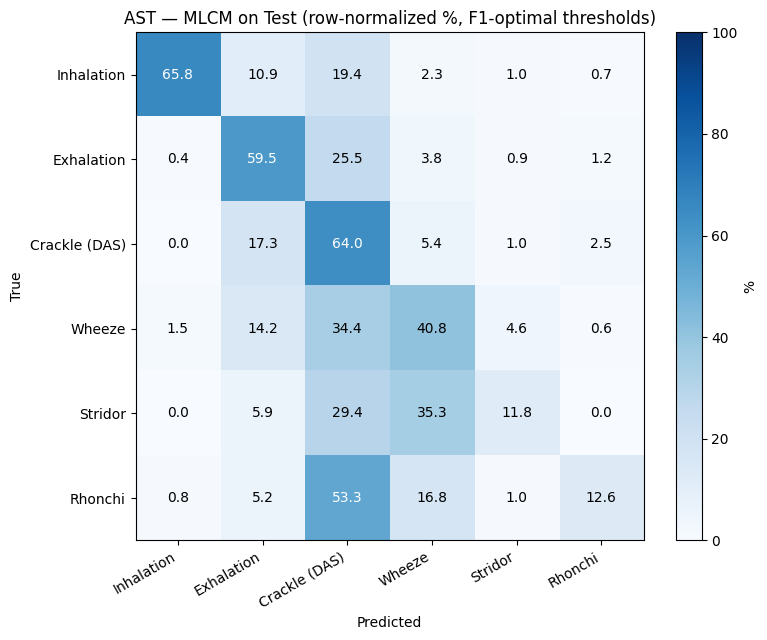

No-predicted-label (NPL) %: {'Inhalation': np.float64(0.0), 'Exhalation': np.float64(8.6), 'Crackle (DAS)': np.float64(9.8), 'Wheeze': np.float64(4.0), 'Stridor': np.float64(17.6), 'Rhonchi': np.float64(10.2)} | NTL row count: 11


,Class,TP,FP,FN,TN
0,Inhalation,1935,21,0,0
1,Exhalation,743,378,207,628
2,Crackle (DAS),307,917,61,671
3,Wheeze,276,137,129,1414
4,Stridor,2,35,10,1909
5,Rhonchi,48,22,248,1638


In [ ]:
# الخطوة 7: مصفوفة الارتباك متعددة التصنيفات MLCM (Heydarian 2022) بالنسب المئوية
import matplotlib.pyplot as plt, pandas as pd
from IPython.display import display

FULL = ['Inhalation', 'Exhalation', 'Crackle (DAS)', 'Wheeze', 'Stridor', 'Rhonchi']
test_prob, thr_f1, Yc_te = np.load(f'{OUT}/ast_test_prob.npy'), np.load(f'{OUT}/ast_thr_f1.npy'), Yte.max(1)
H = (test_prob >= thr_f1).astype(int)

def mlcm(T, P):
    n = T.shape[1]; M = np.zeros((n + 1, n + 1), int)            # last row = NTL, last col = NPL
    for t, p in zip(T.astype(bool), P.astype(bool)):
        ti, pi = np.where(t)[0], np.where(p)[0]
        ok, miss, extra = ti[p[ti]], ti[~p[ti]], pi[~t[pi]]
        M[ok, ok] += 1
        if   len(ti) == 0 and len(pi) == 0: M[n, n] += 1
        elif len(ti) == 0:                  M[n, extra] += 1
        elif len(extra) == 0:               M[miss, n] += 1             # missed labels only
        elif len(miss) == 0:                M[np.ix_(ti, extra)] += 1   # extra labels only
        else:                               M[np.ix_(miss, extra)] += 1 # missed + extra
    return M

M = mlcm(Yc_te, H); R = 100 * M / np.maximum(M.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(R[:6, :6], cmap='Blues', vmin=0, vmax=100)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f'{R[i, j]:.1f}', ha='center', va='center', fontsize=10,
                color='white' if R[i, j] > 50 else 'black')
ax.set_xticks(range(6), FULL, rotation=30, ha='right'); ax.set_yticks(range(6), FULL)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('AST — MLCM on Test (row-normalized %, F1-optimal thresholds)')
fig.colorbar(im, fraction=0.046, label='%'); plt.tight_layout()
plt.savefig(f'{OUT}/mlcm_ast.png', dpi=300); plt.show()

print('No-predicted-label (NPL) %:', dict(zip(FULL, R[:6, 6].round(1))), '| NTL row count:', M[6].sum())
tp = ((H == 1) & (Yc_te == 1)).sum(0); fp = ((H == 1) & (Yc_te == 0)).sum(0)
fn = ((H == 0) & (Yc_te == 1)).sum(0); tn = ((H == 0) & (Yc_te == 0)).sum(0)
cnt = pd.DataFrame({'Class': FULL, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn}); display(cnt)
cnt.to_csv(f'{OUT}/tp_fp_fn_tn_ast.csv', index=False); np.save(f'{OUT}/mlcm_ast_counts.npy', M)

Alert threshold (OOF F1) = 0.43 | OOF AUC = 0.853 | Test abnormal = 957/1956 | TP 849  FN 108  FP 468  TN 531


Accuracy,Precision,Sensitivity,Specificity,F1-score,AUC
0.706,0.645,0.887,0.532,0.747,0.811


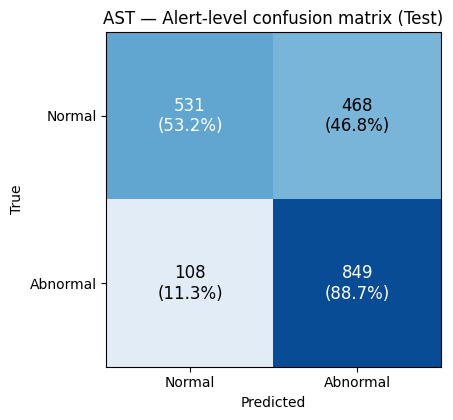

In [ ]:
# الخطوة 8: تقييم مستوى التنبيه (غير طبيعي مقابل طبيعي) بعتبة F1 من OOF
from sklearn.metrics import f1_score, confusion_matrix, roc_auc_score

AB = [2, 3, 4, 5]                                              # Crackle, Wheeze, Stridor, Rhonchi
oof, Yc_tr = np.load(f'{OUT}/ast_oof_prob.npy'), Ytr.max(1)
y_tr, s_tr = Yc_tr[:, AB].max(1), oof[:, AB].max(1)
y_te, s_te = Yc_te[:, AB].max(1), test_prob[:, AB].max(1)
G = np.round(np.arange(0.01, 1.0, 0.01), 2)
thr_al = G[int(np.argmax([f1_score(y_tr, s_tr >= t) for t in G]))]
h = (s_te >= thr_al).astype(int); tn, fp, fn, tp = confusion_matrix(y_te, h).ravel()

res = pd.DataFrame([{'Accuracy': (tp + tn) / len(y_te), 'Precision': tp / (tp + fp),
                     'Sensitivity': tp / (tp + fn), 'Specificity': tn / (tn + fp),
                     'F1-score': 2 * tp / (2 * tp + fp + fn), 'AUC': roc_auc_score(y_te, s_te)}])
print(f'Alert threshold (OOF F1) = {thr_al} | OOF AUC = {roc_auc_score(y_tr, s_tr):.3f} | '
      f'Test abnormal = {int(y_te.sum())}/{len(y_te)} | TP {tp}  FN {fn}  FP {fp}  TN {tn}')
display(res.style.format(precision=3).hide(axis='index').set_caption('AST — Alert level (Abnormal vs Normal), Test')
        .set_table_styles(CSS if 'CSS' in globals() else []))
res.to_csv(f'{OUT}/ast_alert_level_results.csv', index=False)

C2 = np.array([[tn, fp], [fn, tp]]); R2 = 100 * C2 / C2.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(5, 4.3))
ax.imshow(R2, cmap='Blues', vmin=0, vmax=100)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{C2[i, j]}\n({R2[i, j]:.1f}%)', ha='center', va='center', fontsize=12,
                color='white' if R2[i, j] > 50 else 'black')
ax.set_xticks([0, 1], ['Normal', 'Abnormal']); ax.set_yticks([0, 1], ['Normal', 'Abnormal'])
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title('AST — Alert-level confusion matrix (Test)')
plt.tight_layout(); plt.savefig(f'{OUT}/alert_cm_ast.png', dpi=300); plt.show()

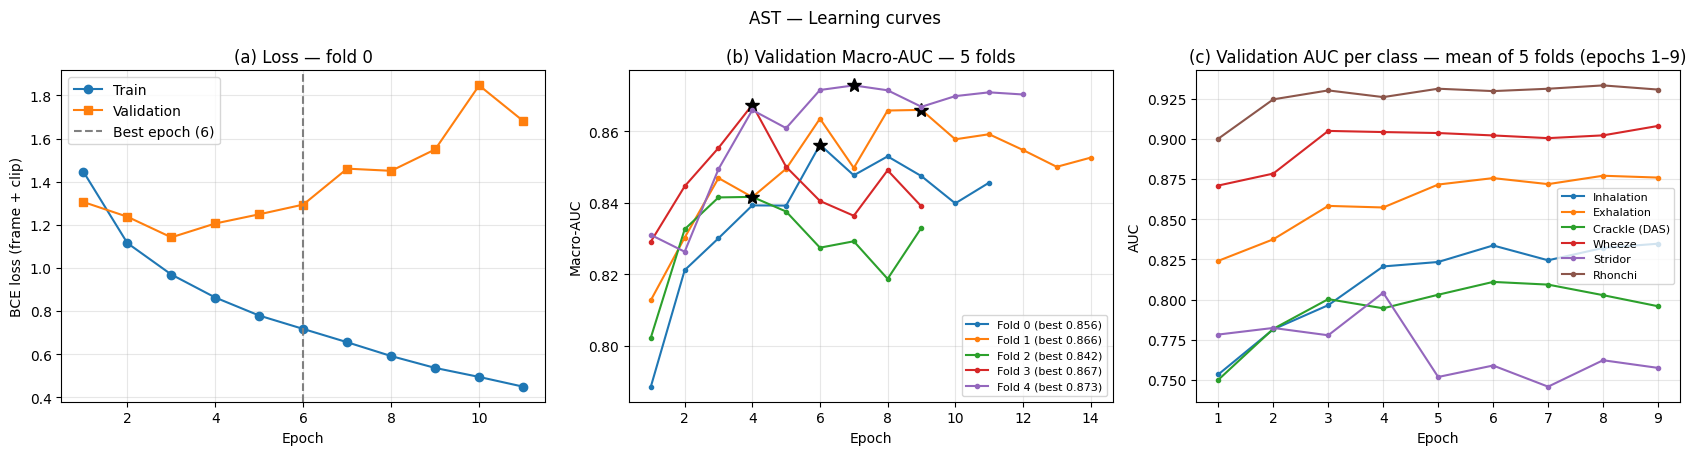

In [ ]:
# الخطوة 9: منحنيات التعلّم (3 لوحات) لـ AST
import json
HS = [json.load(open(f'{OUT}/ast_fold{k}_hist.json')) for k in range(5)]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))

h0 = HS[0]; e = np.arange(1, len(h0['tr_loss']) + 1)
ax[0].plot(e, h0['tr_loss'], 'o-', label='Train'); ax[0].plot(e, h0['va_loss'], 's-', label='Validation')
ax[0].axvline(h0['best_ep'] + 1, ls='--', c='gray', label=f'Best epoch ({h0["best_ep"] + 1})')
ax[0].set(title='(a) Loss — fold 0', xlabel='Epoch', ylabel='BCE loss (frame + clip)'); ax[0].legend()

for k, h in enumerate(HS):
    ax[1].plot(np.arange(1, len(h['va_auc']) + 1), h['va_auc'], 'o-', ms=3, label=f'Fold {k} (best {max(h["va_auc"]):.3f})')
    ax[1].plot(h['best_ep'] + 1, max(h['va_auc']), 'k*', ms=10)
ax[1].set(title='(b) Validation Macro-AUC — 5 folds', xlabel='Epoch', ylabel='Macro-AUC'); ax[1].legend(fontsize=8)

n = min(len(h['va_auc_cls']) for h in HS)
A = np.array([h['va_auc_cls'][:n] for h in HS]).mean(0)          # (n, 6) mean of 5 folds
for c in range(6): ax[2].plot(np.arange(1, n + 1), A[:, c], 'o-', ms=3, label=FULL[c])
ax[2].set(title=f'(c) Validation AUC per class — mean of 5 folds (epochs 1–{n})',
          xlabel='Epoch', ylabel='AUC'); ax[2].legend(fontsize=8)

for a in ax: a.grid(alpha=0.3)
plt.suptitle('AST — Learning curves'); plt.tight_layout()
plt.savefig(f'{OUT}/learning_curves_ast.png', dpi=300); plt.show()

In [ ]:
# الخطوة 10: خرائط Grad-CAM لـ AST (متوسط 5 folds) مع Focus ratio لكل صنف
import librosa
from scipy.ndimage import gaussian_filter
from matplotlib.patches import Rectangle

def cam_ast(m, x, c):
    h = m.ast(input_values=x).last_hidden_state; h.retain_grad()
    t = h[:, 2:].reshape(1, 12, 101, 768).mean(1)
    fl = F.interpolate(m.head(t).transpose(1, 2), size=TP, mode='linear', align_corners=False)[..., :T]
    m.zero_grad(); fl[0, c].mean().backward()
    A, Gd = h[0, 2:].detach(), h.grad[0, 2:]
    cam = F.relu((A * Gd.mean(0)).sum(-1)).reshape(1, 1, 12, 101)
    cam = F.interpolate(cam, size=(128, TP), mode='bilinear', align_corners=False)[0, 0, :, :T]
    return (cam / (cam.max() + 1e-8)).detach().cpu().numpy()

ex = [int(np.where(Yc_te[:, c] == 1)[0][np.argmax(test_prob[Yc_te[:, c] == 1, c])]) for c in range(6)]
CAMS = np.zeros((6, 128, T))
for k in range(5):
    m = ASTFrame().cuda(); m.load_state_dict(torch.load(f'{OUT}/ast_fold{k}.pt', map_location='cuda')); m.eval()
    for c, j in enumerate(ex):
        x = F.pad((torch.from_numpy(Xte[j].astype(np.float32)) - MU) / (2 * SD), (0, TP - T)).T[None].cuda()
        CAMS[c] += cam_ast(m, x, c) / 5
    del m; torch.cuda.empty_cache()
CAMS = np.stack([gaussian_filter(cm, 2) for cm in CAMS])

mel_f = librosa.mel_frequencies(n_mels=128, fmin=50, fmax=2000); W = 313      # 5 s = 313 frames
fig, axs = plt.subplots(2, 3, figsize=(18, 8)); rows = []
for c, (j, ax) in enumerate(zip(ex, axs.ravel())):
    ev, prof = Yte[j, :, c].astype(bool), CAMS[c].sum(0)
    cov = ev.mean(); fr = (prof[ev].sum() / prof.sum()) / cov
    rows.append([FULL[c], j, test_prob[j, c], cov, fr, 1 / cov])
    a = int(np.clip(np.argmax(np.convolve(prof, np.ones(W), 'same')) - W // 2, 0, T - W)); b = a + W
    ext = [a * 0.016, b * 0.016, -0.5, 127.5]
    ax.imshow(Xte[j, :, a:b].astype(np.float32), aspect='auto', origin='lower', cmap='gray', extent=ext)
    ax.imshow(CAMS[c][:, a:b], aspect='auto', origin='lower', cmap='jet', alpha=0.45, extent=ext, vmin=0, vmax=1)
    d = np.diff(np.r_[0, ev[a:b].astype(int), 0])
    for s0, e0 in zip(np.where(d == 1)[0], np.where(d == -1)[0]):
        ax.add_patch(Rectangle(((a + s0) * 0.016, -0.5), (e0 - s0) * 0.016, 128, fill=False, ls='--', lw=1.5, ec='white'))
    yt = [0, 32, 64, 96, 127]; ax.set_yticks(yt, [f'{mel_f[i]:.0f}' for i in yt])
    ax.set(title=f'{FULL[c]} — p = {test_prob[j, c]:.2f} | Focus ratio = {fr:.2f}', xlabel='Time (s)', ylabel='Frequency (Hz)')
plt.suptitle('AST — Grad-CAM on Test (mean of 5 folds); dashed boxes = annotated events'); plt.tight_layout()
plt.savefig(f'{OUT}/gradcam_ast.png', dpi=300); plt.show()

fr_df = pd.DataFrame(rows, columns=['Class', 'Test index', 'Probability', 'Event coverage', 'Focus ratio', 'Max possible'])
display(fr_df.style.format(precision=2).hide(axis='index')); fr_df.to_csv(f'{OUT}/gradcam_ast_focus.csv', index=False)

In [ ]:
# الخطوة 11: جدول مقارنة موحّد للخوارزميات الثلاث (نفس العتبات من OOF ونفس Test)
S2 = '/content/drive/MyDrive/specs_v2'
key = lambda a: np.array([os.path.splitext(os.path.basename(str(s)))[0] for s in a])
ntr, nte = key(np.load(f'{C}/train_names.npy')), key(np.load(f'{C}/test_names.npy'))
Yc_tr, Yc_te = Ytr.max(1), Yte.max(1)

def align(src, P, ref):
    pos = {n: i for i, n in enumerate(src)}; idx = np.array([pos.get(n, -1) for n in ref])
    assert (idx >= 0).all(), f'{(idx < 0).sum()} names not matched'
    return P[idx]

crnn_oof = np.zeros((len(Xtr), 6), np.float32)
for k in range(5): crnn_oof[fold == k] = np.load(f'{C}/crnn_oof_fold{k}.npy')
PRED = {'EfficientAT': (align(key(np.load(f'{S2}/train_files.npy')), np.load(f'{S2}/oof_probs_v5.npy'), ntr),
                        align(key(np.load(f'{S2}/test_files.npy')),  np.load(f'{S2}/test_probs_v5.npy'), nte)),
        'CNN-BiGRU':   (crnn_oof, np.load(f'{C}/crnn_test_prob.npy')),
        'AST':         (np.load(f'{OUT}/ast_oof_prob.npy'), np.load(f'{OUT}/ast_test_prob.npy'))}
for a, (po, pt) in PRED.items(): print(a, 'oof', po.shape, 'test', pt.shape)

G, AB = np.round(np.arange(0.01, 1.0, 0.01), 2), [2, 3, 4, 5]
F1 = lambda y, h: f1_score(y, h, zero_division=0)
def thr_of(y, p, fn): return np.array([G[int(np.argmax([fn(y[:, c], p[:, c] >= t) for t in G]))] for c in range(6)])
def macro(y, p, thr):
    h = p >= thr
    m = [[accuracy_score(y[:, c], h[:, c]), precision_score(y[:, c], h[:, c], zero_division=0),
          recall_score(y[:, c], h[:, c], zero_division=0), F1(y[:, c], h[:, c]), roc_auc_score(y[:, c], p[:, c])] for c in range(6)]
    return np.mean(m, 0)

R_f1, R_acc, R_al = [], [], []
for a, (po, pt) in PRED.items():
    R_f1.append([a, *macro(Yc_te, pt, thr_of(Yc_tr, po, F1))])
    R_acc.append([a, *macro(Yc_te, pt, thr_of(Yc_tr, po, accuracy_score))])
    ya, sa, yb, sb = Yc_tr[:, AB].max(1), po[:, AB].max(1), Yc_te[:, AB].max(1), pt[:, AB].max(1)
    t = G[int(np.argmax([f1_score(ya, sa >= g) for g in G]))]
    tn, fp, fn, tp = confusion_matrix(yb, sb >= t).ravel()
    R_al.append([a, (tp + tn) / len(yb), tp / (tp + fp), tp / (tp + fn), tn / (tn + fp),
                 2 * tp / (2 * tp + fp + fn), roc_auc_score(yb, sb), int(fn), int(fp)])

MC = ['Algorithm', 'Macro-Accuracy', 'Macro-Precision', 'Macro-Recall', 'Macro-F1', 'Macro-AUC']
AC = ['Algorithm', 'Accuracy', 'Precision', 'Sensitivity', 'Specificity', 'F1-score', 'AUC', 'Missed (FN)', 'False alarms (FP)']
for rows, cols, cap, f in [(R_f1, MC, 'Test — F1-optimal thresholds (OOF)', 'cmp_f1thr'),
                           (R_acc, MC, 'Test — Accuracy-optimal thresholds (OOF)', 'cmp_accthr'),
                           (R_al, AC, 'Test — Alert level (Abnormal vs Normal)', 'cmp_alert')]:
    d = pd.DataFrame(rows, columns=cols); d.to_csv(f'{OUT}/{f}.csv', index=False)
    display(d.style.format(precision=3).hide(axis='index').set_caption(cap).set_table_styles(CSS if 'CSS' in globals() else []))


EfficientAT oof (7809, 6) test (1956, 6)
CNN-BiGRU oof (7809, 6) test (1956, 6)
AST oof (7809, 6) test (1956, 6)


Algorithm,Macro-Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Macro-AUC
EfficientAT,0.808,0.531,0.596,0.502,0.754
CNN-BiGRU,0.820,0.544,0.558,0.492,0.776
AST,0.816,0.552,0.604,0.519,0.793


Algorithm,Macro-Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Macro-AUC
EfficientAT,0.849,0.577,0.450,0.465,0.754
CNN-BiGRU,0.860,0.578,0.394,0.427,0.776
AST,0.859,0.589,0.465,0.480,0.793


Algorithm,Accuracy,Precision,Sensitivity,Specificity,F1-score,AUC,Missed (FN),False alarms (FP)
EfficientAT,0.701,0.655,0.822,0.585,0.729,0.785,170,415
CNN-BiGRU,0.651,0.621,0.734,0.572,0.673,0.727,255,428
AST,0.706,0.645,0.887,0.532,0.747,0.811,108,468


In [ ]:
# Idea: matched retraining of AST (Audio Spectrogram Transformer) under the BEATs protocol
# Goal: same 382-session folds, 7 outputs (6 classes + Abnormal), <=25 epochs, patience 5, selection S
# Source: Gong et al., Interspeech 2021; frame head after Schmid et al. 2025
from google.colab import drive; drive.mount('/content/drive')
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F, os, time
from transformers import ASTModel
C   = '/content/drive/MyDrive/crnn_cache'
OUT = '/content/drive/MyDrive/matched_baselines/ast'; os.makedirs(OUT, exist_ok=True)
dev = 'cuda'

# ---- data (cache is already z-scored log-mel, 4 kHz, 128 x 938)
Xtr = np.load(f'{C}/train_X.npy'); Xte = np.load(f'{C}/test_X.npy')
def add_abn(Yf):                                   # frame labels (N,938,6) -> (N,938,7)
    Yf = np.asarray(Yf, dtype=np.uint8); assert Yf.shape[1:] == (938, 6), Yf.shape
    return np.concatenate([Yf, Yf[..., 2:6].max(-1, keepdims=True)], -1)
Yf_tr = add_abn(np.load(f'{C}/train_Yf.npy')); Yf_te = add_abn(np.load(f'{C}/test_Yf.npy'))
Ytr, Yte = Yf_tr.max(1), Yf_te.max(1)              # recording-level labels
fold = np.load(f'{C}/train_fold.npy')
print('train', Xtr.shape, '| test', Xte.shape, '| positives', Ytr.sum(0), '| fold sizes', np.bincount(fold))

# ---- model: AST backbone + frame-level head (7 outputs)
MEAN, STD = -8.5267, 2.4603                        # AST input scaling kept as in the original AST runs
class ASTFrame(nn.Module):
    def __init__(s, n=7):
        super().__init__()
        s.ast  = ASTModel.from_pretrained('MIT/ast-finetuned-audioset-10-10-0.4593')
        s.head = nn.Sequential(nn.LayerNorm(768), nn.Dropout(0.1), nn.Linear(768, n))
    def forward(s, x):                                            # x: (B,128,938)
        x = (x - MEAN) / (2 * STD)
        x = F.pad(x, (0, 1024 - x.shape[-1])).transpose(1, 2)     # (B,1024,128), keeps pretrained positions
        h = s.ast(input_values=x).last_hidden_state[:, 2:]        # (B,12*101,768) patch tokens
        h = h.reshape(h.shape[0], 12, 101, 768).mean(1)           # mean over frequency patches
        z = s.head(h).transpose(1, 2)                             # (B,7,101)
        z = F.interpolate(z, size=1024, mode='linear', align_corners=False)[..., :938]
        return z.transpose(1, 2)                                  # frame logits (B,938,7)

# ---- memory check: one batch of 16 with backward pass
m = ASTFrame().to(dev)
print('params: %.1f M' % (sum(p.numel() for p in m.parameters()) / 1e6))
xb = torch.from_numpy(Xtr[:16].astype(np.float32)).to(dev)
with torch.autocast('cuda', dtype=torch.float16):
    out = m(xb)
out.float().mean().backward()
print('output', tuple(out.shape), '| peak GPU %.1f GB' % (torch.cuda.max_memory_allocated() / 1e9))
del m, xb, out; torch.cuda.empty_cache()

Mounted at /content/drive
train (7809, 128, 938) | test (1956, 128, 938) | positives [7510 4593 3076 2253  253  944 4999] | fold sizes [2051 1334 1341 1510 1573]


config.json:   0%|          | 0.00/26.8k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.dense.bias       | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


params: 86.2 M
output (16, 938, 7) | peak GPU 8.0 GB


In [ ]:
# Idea: AST training under the matched protocol (5 folds, resumable after disconnect)
# Goal: per-fold best model by S = 0.5*(6-class Macro-AUC + Abnormal AUC) on validation
# Source: frame+recording BCE (Hsu et al. 2021); SpecAugment (Park et al. 2019)
import math
from sklearn.metrics import roc_auc_score
EPOCHS, PAT, BS = 25, 5, 16

def rec_prob(z):                                   # frame logits (B,938,7) -> recording prob (B,7)
    p = torch.sigmoid(z.float()).transpose(1, 2)
    return F.avg_pool1d(p, 9, 1, 4).amax(-1)        # 9-frame moving average, max over time

def specaug(x):                                    # 2 frequency masks (<=16), 1 time mask (<=40), per sample
    B, Fq, T = x.shape; d = x.device
    for size, n, axis in [(16, 2, 1), (40, 1, 2)]:
        L = Fq if axis == 1 else T
        r = torch.arange(L, device=d).view((1, L, 1) if axis == 1 else (1, 1, L))
        for _ in range(n):
            w  = torch.randint(0, size + 1, (B, 1, 1), device=d)
            s0 = (torch.rand(B, 1, 1, device=d) * (L - w)).long()
            x  = x.masked_fill((r >= s0) & (r < s0 + w), 0.)
    return x

def score(y, p):
    auc = [roc_auc_score(y[:, c], p[:, c]) for c in range(7)]
    return 0.5 * (np.mean(auc[:6]) + auc[6]), np.mean(auc[:6])

def predict(model, X, bs=32):
    model.eval(); out = []
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        for b in range(0, len(X), bs):
            out.append(rec_prob(model(torch.from_numpy(X[b:b+bs].astype(np.float32)).to(dev))).cpu().numpy())
    return np.concatenate(out)

for k in range(5):
    if os.path.exists(f'{OUT}/fold{k}_val_prob.npy'): print(f'fold {k} already done'); continue
    torch.manual_seed(42 + k)
    tr, va = np.where(fold != k)[0], np.where(fold == k)[0]
    pf = Yf_tr[tr].mean((0, 1)); pc = Ytr[tr].mean(0)
    pw_f = torch.tensor(np.clip((1 - pf) / np.maximum(pf, 1e-6), 1, 10), dtype=torch.float32, device=dev)
    pw_c = torch.tensor(np.clip((1 - pc) / np.maximum(pc, 1e-6), 1, 10), dtype=torch.float32, device=dev)

    m = ASTFrame().to(dev)
    opt = torch.optim.AdamW([{'params': m.ast.parameters(), 'lr': 2e-5},
                             {'params': m.head.parameters(), 'lr': 1e-3}], weight_decay=1e-4)
    spe = len(tr) // BS; tot = EPOCHS * spe
    sch = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: s / spe if s < spe else 0.5 * (1 + math.cos(math.pi * (s - spe) / (tot - spe))))
    scaler = torch.amp.GradScaler('cuda')

    rf = f'{OUT}/fold{k}_resume.pt'; ep0, best, bad, vbest = 0, -1., 0, None
    if os.path.exists(rf):
        ck = torch.load(rf, map_location='cpu', weights_only=False)
        m.load_state_dict(ck['m']); opt.load_state_dict(ck['o']); sch.load_state_dict(ck['s']); scaler.load_state_dict(ck['sc'])
        ep0, best, bad, vbest = ck['ep'] + 1, ck['best'], ck['bad'], ck['vp']; print(f'fold {k} resumed at epoch {ep0}')

    for ep in range(ep0, EPOCHS):
        t0 = time.time(); m.train(); rng = np.random.default_rng(1000 * k + ep); perm = rng.permutation(tr)
        for i in range(spe):
            idx = np.sort(perm[i*BS:(i+1)*BS])
            xb = specaug(torch.from_numpy(Xtr[idx].astype(np.float32)).to(dev))
            yf = torch.from_numpy(Yf_tr[idx]).float().to(dev); yc = torch.from_numpy(Ytr[idx]).float().to(dev)
            with torch.autocast('cuda', dtype=torch.float16):
                z = m(xb)
            z = z.float(); p = rec_prob(z).clamp(1e-6, 1 - 1e-6)
            loss = F.binary_cross_entropy_with_logits(z, yf, pos_weight=pw_f) \
                   - (pw_c * yc * torch.log(p) + (1 - yc) * torch.log(1 - p)).mean()
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(m.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sch.step()
        vp = predict(m, Xtr[va]); S, a6 = score(Ytr[va], vp)
        if S > best:
            best, bad, vbest = S, 0, vp
            torch.save({n: t.half() for n, t in m.state_dict().items()}, f'{OUT}/fold{k}_best.pt')
        else:
            bad += 1
        torch.save({'m': m.state_dict(), 'o': opt.state_dict(), 's': sch.state_dict(), 'sc': scaler.state_dict(),
                    'ep': ep, 'best': best, 'bad': bad, 'vp': vbest}, rf)
        print(f'fold {k} ep {ep:2d} | loss {loss.item():.3f} | S {S:.4f} (6-class AUC {a6:.4f}) | best {best:.4f} | {time.time()-t0:.0f}s')
        if bad >= PAT: break
    np.save(f'{OUT}/fold{k}_val_prob.npy', vbest); os.remove(rf)
    print(f'== fold {k} finished: best S {best:.4f}')
    del m, opt; torch.cuda.empty_cache()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.dense.bias       | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_4914/3985517595.py:68: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sch.step()


fold 0 ep  0 | loss 1.101 | S 0.8165 (6-class AUC 0.7885) | best 0.8165 | 434s
fold 0 ep  1 | loss 1.222 | S 0.8452 (6-class AUC 0.8207) | best 0.8452 | 458s
fold 0 ep  2 | loss 0.694 | S 0.8536 (6-class AUC 0.8369) | best 0.8536 | 442s
fold 0 ep  3 | loss 0.883 | S 0.8587 (6-class AUC 0.8390) | best 0.8587 | 457s
fold 0 ep  4 | loss 0.801 | S 0.8566 (6-class AUC 0.8460) | best 0.8587 | 442s
fold 0 ep  5 | loss 0.571 | S 0.8659 (6-class AUC 0.8497) | best 0.8659 | 459s
fold 0 ep  6 | loss 0.557 | S 0.8632 (6-class AUC 0.8372) | best 0.8659 | 447s
fold 0 ep  7 | loss 0.564 | S 0.8684 (6-class AUC 0.8507) | best 0.8684 | 443s
fold 0 ep  8 | loss 0.370 | S 0.8658 (6-class AUC 0.8511) | best 0.8684 | 446s
fold 0 ep  9 | loss 0.428 | S 0.8553 (6-class AUC 0.8491) | best 0.8684 | 437s
fold 0 ep 10 | loss 0.342 | S 0.8546 (6-class AUC 0.8449) | best 0.8684 | 443s
fold 0 ep 11 | loss 0.358 | S 0.8534 (6-class AUC 0.8388) | best 0.8684 | 443s
fold 0 ep 12 | loss 0.311 | S 0.8662 (6-class AUC 0.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.dense.bias       | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_4914/3985517595.py:68: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sch.step()


fold 1 ep  0 | loss 1.020 | S 0.8491 (6-class AUC 0.8159) | best 0.8491 | 483s
fold 1 ep  1 | loss 1.188 | S 0.8694 (6-class AUC 0.8400) | best 0.8694 | 476s
fold 1 ep  2 | loss 0.692 | S 0.8722 (6-class AUC 0.8452) | best 0.8722 | 475s
fold 1 ep  3 | loss 0.825 | S 0.8802 (6-class AUC 0.8570) | best 0.8802 | 471s
fold 1 ep  4 | loss 0.959 | S 0.8851 (6-class AUC 0.8605) | best 0.8851 | 476s
fold 1 ep  5 | loss 0.889 | S 0.8717 (6-class AUC 0.8488) | best 0.8851 | 479s
fold 1 ep  6 | loss 0.617 | S 0.8862 (6-class AUC 0.8625) | best 0.8862 | 485s
fold 1 ep  7 | loss 0.475 | S 0.8812 (6-class AUC 0.8564) | best 0.8862 | 472s
fold 1 ep  8 | loss 0.654 | S 0.8754 (6-class AUC 0.8527) | best 0.8862 | 472s
fold 1 ep  9 | loss 0.436 | S 0.8788 (6-class AUC 0.8515) | best 0.8862 | 473s
fold 1 ep 10 | loss 0.339 | S 0.8741 (6-class AUC 0.8502) | best 0.8862 | 481s
fold 1 ep 11 | loss 0.205 | S 0.8762 (6-class AUC 0.8444) | best 0.8862 | 481s
== fold 1 finished: best S 0.8862


... (5 outputs left out)

fold 3 ep  0 | loss 1.328 | S 0.8480 (6-class AUC 0.8278) | best 0.8480 | 475s
fold 3 ep  1 | loss 0.809 | S 0.8824 (6-class AUC 0.8519) | best 0.8824 | 484s
fold 3 ep  2 | loss 1.036 | S 0.8841 (6-class AUC 0.8621) | best 0.8841 | 472s
fold 3 ep  3 | loss 0.952 | S 0.8831 (6-class AUC 0.8550) | best 0.8841 | 470s
fold 3 ep  4 | loss 0.673 | S 0.8742 (6-class AUC 0.8375) | best 0.8841 | 474s
fold 3 ep  5 | loss 0.514 | S 0.8764 (6-class AUC 0.8437) | best 0.8841 | 469s
fold 3 ep  6 | loss 0.627 | S 0.8826 (6-class AUC 0.8595) | best 0.8841 | 484s
fold 3 ep  7 | loss 0.475 | S 0.8801 (6-class AUC 0.8450) | best 0.8841 | 482s
== fold 3 finished: best S 0.8841


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.dense.bias       | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_4914/3985517595.py:68: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sch.step()


fold 4 ep  0 | loss 0.960 | S 0.8212 (6-class AUC 0.8126) | best 0.8212 | 483s
fold 4 ep  1 | loss 0.768 | S 0.8501 (6-class AUC 0.8293) | best 0.8501 | 473s
fold 4 ep  2 | loss 0.743 | S 0.8668 (6-class AUC 0.8591) | best 0.8668 | 464s
fold 4 ep  3 | loss 0.642 | S 0.8801 (6-class AUC 0.8602) | best 0.8801 | 473s
fold 4 ep  4 | loss 0.816 | S 0.8722 (6-class AUC 0.8693) | best 0.8801 | 473s
fold 4 ep  5 | loss 0.603 | S 0.8779 (6-class AUC 0.8662) | best 0.8801 | 471s
fold 4 ep  6 | loss 0.393 | S 0.8785 (6-class AUC 0.8736) | best 0.8801 | 469s
fold 4 ep  7 | loss 0.446 | S 0.8673 (6-class AUC 0.8714) | best 0.8801 | 471s
fold 4 ep  8 | loss 0.748 | S 0.8741 (6-class AUC 0.8661) | best 0.8801 | 473s
== fold 4 finished: best S 0.8801


In [ ]:
# Idea: matched evaluation of AST under the BEATs protocol
# Goal: 5-fold ensemble on the 1,956 test recordings + OOF Accuracy/F1-optimal thresholds
# Source: threshold moving on OOF (Lipton et al. 2014)
import pandas as pd, io, contextlib
CLS = ['Inhalation','Exhalation','Crackle','Wheeze','Stridor','Rhonchi','Abnormal']

# 1) OOF probabilities from saved validation predictions
oof = np.zeros(Ytr.shape, dtype=np.float32)
for k in range(5):
    oof[fold == k] = np.load(f'{OUT}/fold{k}_val_prob.npy')

# 2) Test probabilities = mean of the 5 fold models
probs = []
for k in range(5):
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        m = ASTFrame()
    m.load_state_dict(torch.load(f'{OUT}/fold{k}_best.pt', map_location='cpu')); m = m.to(dev).eval()
    probs.append(predict(m, Xte)); print('fold', k, 'predicted')
    del m; torch.cuda.empty_cache()
P = np.mean(probs, 0); np.save(f'{OUT}/test_prob_5fold.npy', P)

# 3) Per-class thresholds on OOF (grid 0.01-0.99)
grid = np.round(np.arange(0.01, 1.0, 0.01), 2)
def best_t(y, p, obj):
    sc = []
    for t in grid:
        yp = p >= t; tp = (yp & (y == 1)).sum(); fp = (yp & (y == 0)).sum(); fn = (~yp & (y == 1)).sum()
        sc.append((yp == y).mean() if obj == 'acc' else 2*tp / max(2*tp + fp + fn, 1))
    return grid[int(np.argmax(sc))]
T = {o: np.array([best_t(Ytr[:, c], oof[:, c], o) for c in range(7)]) for o in ['acc', 'f1']}

# 4) Test metrics
pd.set_option('display.precision', 3)
allrows = []
for o in ['acc', 'f1']:
    rows = []
    for c in range(7):
        y, p = Yte[:, c], P[:, c]; yp = p >= T[o][c]
        tp = (yp & (y == 1)).sum(); fp = (yp & (y == 0)).sum(); fn = (~yp & (y == 1)).sum()
        pr = tp / max(tp + fp, 1); rc = tp / max(tp + fn, 1)
        rows.append(dict(Class=CLS[c], Threshold=T[o][c], Accuracy=(yp == y).mean(), Precision=pr,
                         Recall=rc, F1=2*pr*rc / max(pr + rc, 1e-9), AUC=roc_auc_score(y, p)))
    df = pd.DataFrame(rows); df.insert(0, 'Objective', o); allrows.append(df)
    print(f'\n=== {o.upper()}-optimal thresholds ==='); print(df.drop(columns='Objective').to_string(index=False))
    mac = df[df.Class != 'Abnormal'][['Accuracy','Precision','Recall','F1','AUC']].mean().add_prefix('Macro-')
    print(mac.to_frame().T.to_string(index=False))
pd.concat(allrows).to_csv(f'{OUT}/ast_test_metrics.csv', index=False)
print('\nOOF 6-class Macro-AUC:', round(np.mean([roc_auc_score(Ytr[:, c], oof[:, c]) for c in range(6)]), 4))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.dense.bias       | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


fold 0 predicted


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.dense.bias       | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


fold 1 predicted


... (5 outputs left out)

fold 3 predicted


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.dense.bias       | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


fold 4 predicted

=== ACC-optimal thresholds ===
     Class  Threshold  Accuracy  Precision  Recall    F1   AUC
Inhalation       0.01     0.989      0.989   1.000 0.995 0.905
Exhalation       0.66     0.710      0.680   0.759 0.717 0.793
   Crackle       0.74     0.754      0.379   0.484 0.425 0.731
    Wheeze       0.80     0.854      0.759   0.435 0.553 0.889
   Stridor       0.99     0.994      0.000   0.000 0.000 0.872
   Rhonchi       0.89     0.856      0.769   0.068 0.124 0.640
  Abnormal       0.60     0.777      0.769   0.777 0.773 0.860
 Macro-Accuracy  Macro-Precision  Macro-Recall  Macro-F1  Macro-AUC
          0.859            0.596         0.457     0.469      0.805

=== F1-optimal thresholds ===
     Class  Threshold  Accuracy  Precision  Recall    F1   AUC
Inhalation       0.01     0.989      0.989   1.000 0.995 0.905
Exhalation       0.55     0.662      0.609   0.852 0.710 0.793
   Crackle       0.43     0.550      0.268   0.802 0.401 0.731
    Wheeze       0.65     0.